In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
df=pd.read_csv("AmesHousing.csv")


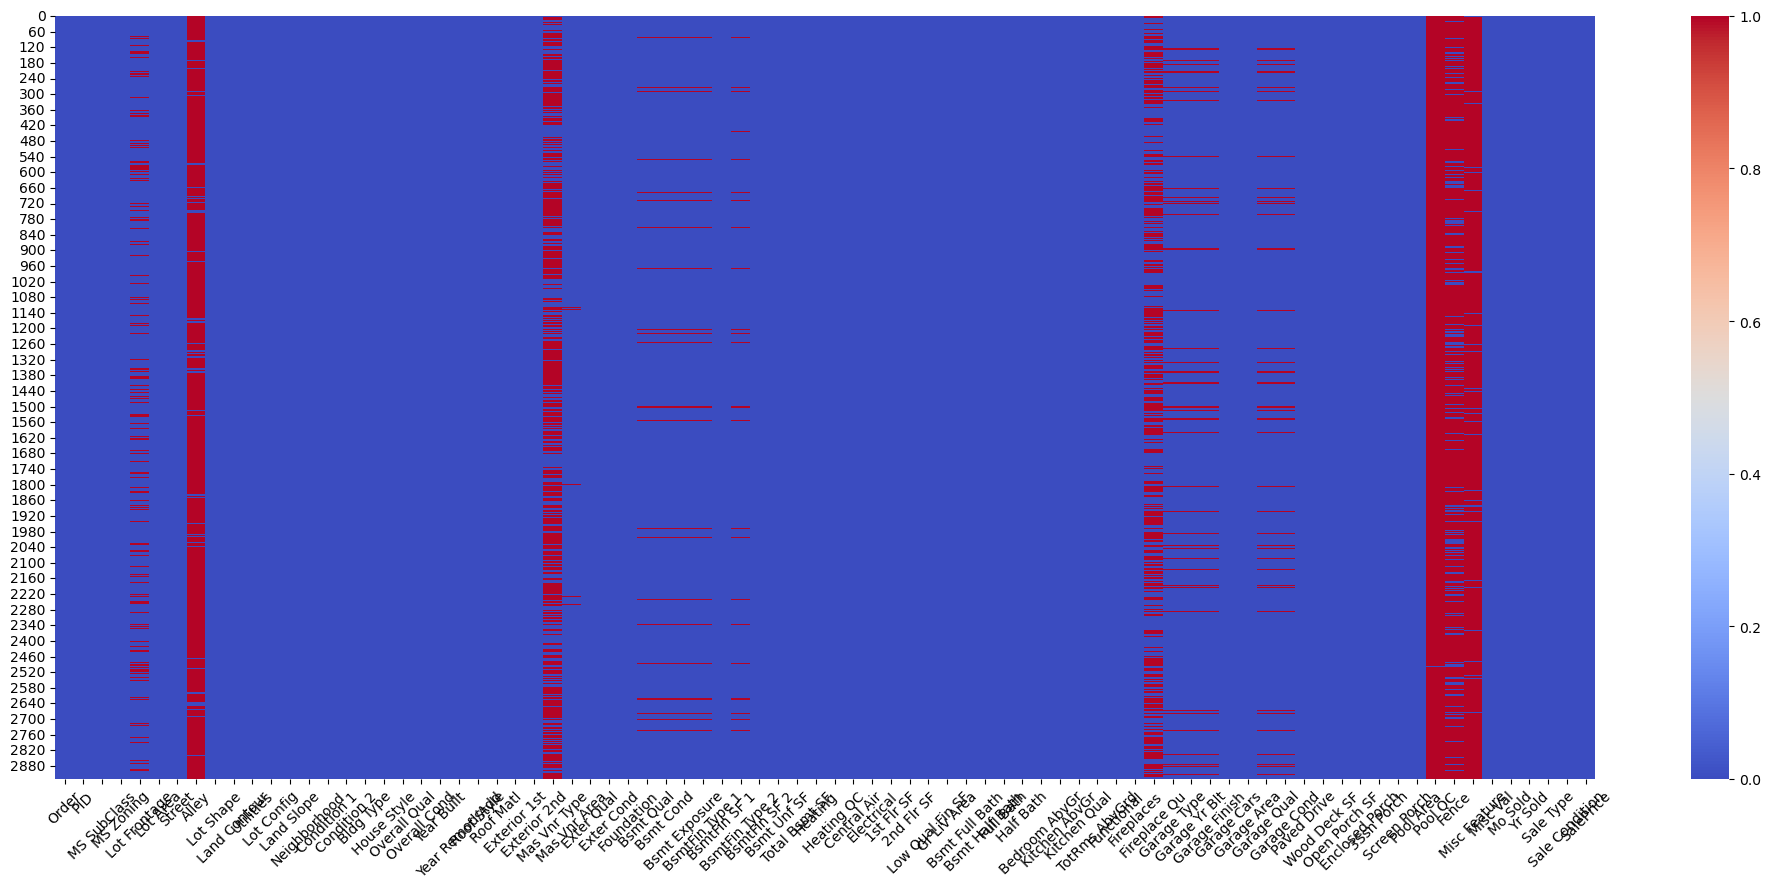

In [4]:
plt.figure(figsize=(20,9))
sns.heatmap(df.isnull(),cmap="coolwarm")
plt.xticks(rotation=45)
plt.tight_layout()

In [105]:
#how to check object data then how many object data
cat_col=df.select_dtypes(include=["object"]).columns
data1=pd.DataFrame(cat_col,columns=["cat_data"])


In [8]:
null_val=pd.DataFrame(df.isnull().sum().sort_values(ascending=False).head(30))
null_val

,0
Pool QC,2917
Misc Feature,2824
Alley,2732
Fence,2358
Mas Vnr Type,1775
Fireplace Qu,1422
Lot Frontage,490
Garage Cond,159
Garage Finish,159
Garage Yr Blt,159


In [1]:
# Pool QC	2917
# Misc Feature	2824
# Alley	2732
# Fence	2358
# Order
# PID
drop_col=["Pool QC","Misc Feature","Alley","Fence","Order","PID"]
df=df.drop(columns=drop_col)


In [24]:
obj_col=pd.DataFrame(df.select_dtypes(include=["object"]).columns,columns=["obj_name"])

In [27]:
int_name=pd.DataFrame(df.select_dtypes(include=["int64"]).columns,columns=["int_name"])

In [30]:
float_name=pd.DataFrame(df.select_dtypes(include=["float64"]).columns,columns=["float_name"])

In [56]:
null_values_name=pd.DataFrame(df.isnull().sum().sort_values(ascending=False).head(23).index,columns=["name"])


In [49]:
pd.DataFrame(df.isnull().sum().sort_values(ascending=False).head(24))

,0
Mas Vnr Type,1775
Fireplace Qu,1422
Lot Frontage,490
Garage Cond,159
Garage Yr Blt,159
Garage Finish,159
Garage Qual,159
Garage Type,157
Bsmt Exposure,83
BsmtFin Type 2,81


In [75]:

cat_data_none2=null_values_name[null_values_name["name"].isin(obj_col["obj_name"])]
cat_data_none=cat_data_none2["name"].tolist()
for col in cat_data_none:
    if col in df.columns:
        df.fillna({col : 'none'},inplace=True)


In [107]:

num_data_median=float_name[float_name["float_name"].isin(null_values_name["name"])]
fill_median=num_data_median["float_name"].tolist()
for col in fill_median:
    if col in df.columns:
        df.fillna({col:df[col].median()},inplace=True)
            
pd.DataFrame(df.isnull().sum().sort_values(ascending=False).head(23))        

,0
MS SubClass,0
Half Bath,0
Fireplace Qu,0
Fireplaces,0
Functional,0
TotRms AbvGrd,0
Kitchen Qual,0
Kitchen AbvGr,0
Bedroom AbvGr,0
Full Bath,0


In [122]:
print(type(df))

df.info()

<class 'pandas.core.frame.DataFrame'>
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2930 entries, 0 to 2929
Data columns (total 76 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   MS SubClass      2930 non-null   int64  
 1   MS Zoning        2930 non-null   object 
 2   Lot Frontage     2930 non-null   float64
 3   Lot Area         2930 non-null   int64  
 4   Street           2930 non-null   object 
 5   Lot Shape        2930 non-null   object 
 6   Land Contour     2930 non-null   object 
 7   Utilities        2930 non-null   object 
 8   Lot Config       2930 non-null   object 
 9   Land Slope       2930 non-null   object 
 10  Neighborhood     2930 non-null   object 
 11  Condition 1      2930 non-null   object 
 12  Condition 2      2930 non-null   object 
 13  Bldg Type        2930 non-null   object 
 14  House Style      2930 non-null   object 
 15  Overall Qual     2930 non-null   int64  
 16  Overall Cond     2930 

In [132]:
num=df.select_dtypes(include=["int64","float64"])
corr=num.corr()
corr_taget=corr["SalePrice"].sort_values(ascending=False)
print(corr_taget.head(10))

SalePrice         1.000000
Overall Qual      0.799262
Gr Liv Area       0.706780
Garage Cars       0.647812
Garage Area       0.640381
Total Bsmt SF     0.632164
1st Flr SF        0.621676
Year Built        0.558426
Full Bath         0.545604
Year Remod/Add    0.532974
Name: SalePrice, dtype: float64


In [136]:
from sklearn.model_selection import train_test_split
x=df.drop(["SalePrice"],axis=1)
y=df["SalePrice"]
x_train, x_test, y_train, y_test=train_test_split(x,y,test_size=0.2,random_state=42)

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [9]:
df=pd.read_csv("C:\\Users\\Adil\\Desktop\\hsdata1.csv")

In [24]:
#this check correlation between two variable
df.isnull().sum().sort_values(ascending=False).head(20)
data=df.select_dtypes(include=["int64","float64"])
corr=data.corr()
corr_target=corr["SalePrice"].sort_values(ascending=False).head(20)
corr_target

SalePrice         1.000000
Overall Qual      0.799262
Gr Liv Area       0.706780
Garage Cars       0.647812
Garage Area       0.640381
Total Bsmt SF     0.632164
1st Flr SF        0.621676
Year Built        0.558426
Full Bath         0.545604
Year Remod/Add    0.532974
Garage Yr Blt     0.508882
Mas Vnr Area      0.502196
TotRms AbvGrd     0.495474
Fireplaces        0.474558
BsmtFin SF 1      0.432862
Lot Frontage      0.340256
Wood Deck SF      0.327143
Open Porch SF     0.312951
Half Bath         0.285056
Bsmt Full Bath    0.275823
Name: SalePrice, dtype: float64

<Axes: xlabel='Overall Qual', ylabel='SalePrice'>

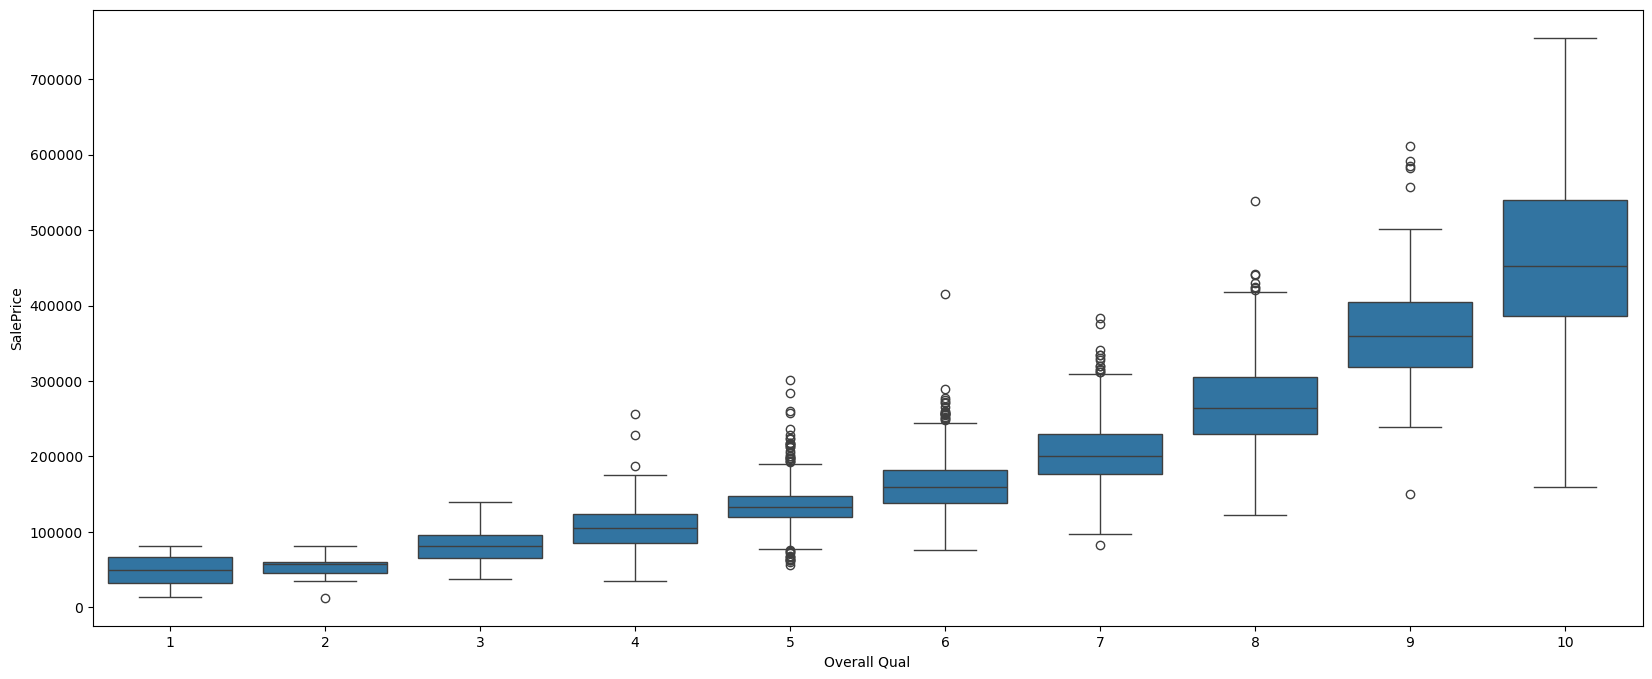

In [28]:
plt.figure(figsize=(20,8))
sns.boxplot(
    data=df,
    x="Overall Qual",
    y="SalePrice")


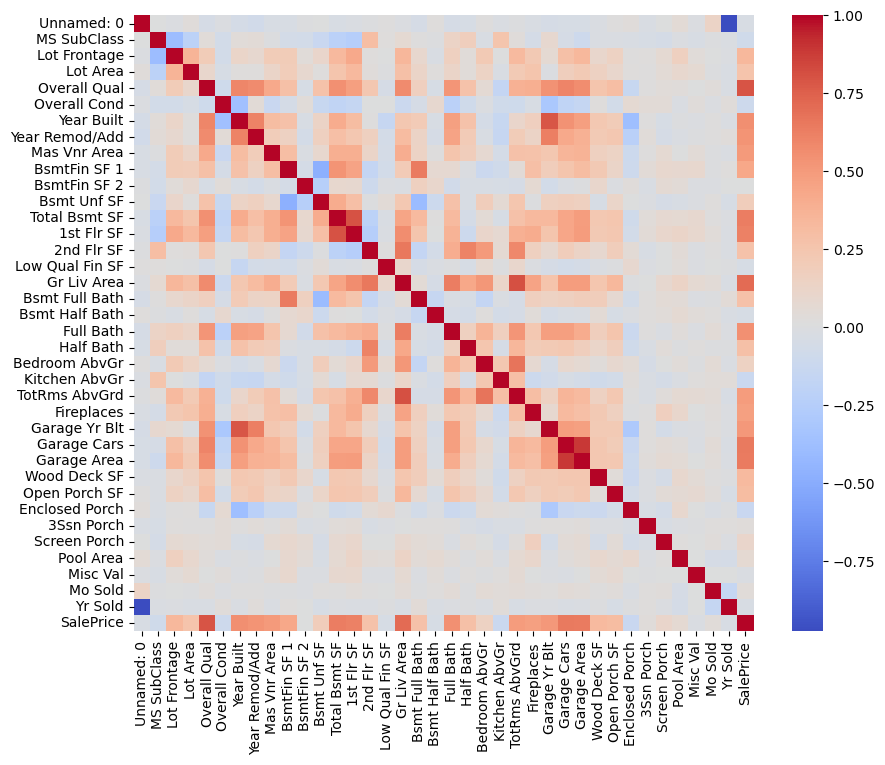

In [38]:
#to check dependency on sale price
plt.figure(figsize=(10,8))
sns.heatmap(corr,cmap="coolwarm",annot=False)
plt.savefig("img8.jpg")

<Axes: xlabel='Gr Liv Area'>

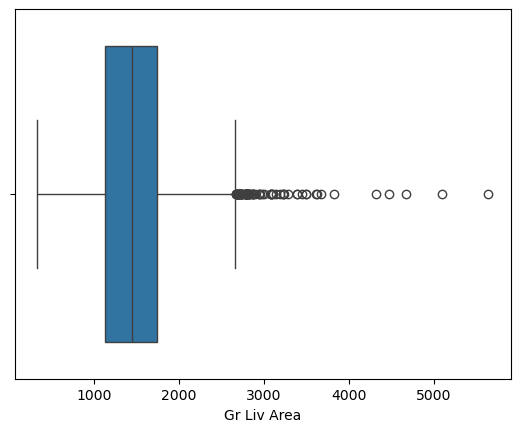

In [42]:
sns.boxplot(
    data=df,
    x=df["Gr Liv Area"])

In [52]:
df=df[df["Gr Liv Area"] < 4500]


In [56]:
#convert numeric but categorical columns string
cat_num_cols=["MS SubClass","Overall Qual","Overall Cond","Mo Sold","Yr Sold"]
for col in cat_num_cols:
    df[col]=df[col].astype(str)
print(df["MS SubClass"].dtype)    

object


In [60]:
#Apply one hot coding
#this use to convert catagorical data in numerical data
en_coded=pd.get_dummies(df,drop_first=True)


In [77]:
list(en_coded.columns)
print("hello")
en_coded.select_dtypes(include=["bool"])

hello


,MS SubClass_150,MS SubClass_160,MS SubClass_180,MS SubClass_190,MS SubClass_20,MS SubClass_30,MS SubClass_40,MS SubClass_45,MS SubClass_50,MS SubClass_60,...,Sale Type_ConLw,Sale Type_New,Sale Type_Oth,Sale Type_VWD,Sale Type_WD,Sale Condition_AdjLand,Sale Condition_Alloca,Sale Condition_Family,Sale Condition_Normal,Sale Condition_Partial
0,False,False,False,False,True,False,False,False,False,False,...,False,False,False,False,True,False,False,False,True,False
1,False,False,False,False,True,False,False,False,False,False,...,False,False,False,False,True,False,False,False,True,False
2,False,False,False,False,True,False,False,False,False,False,...,False,False,False,False,True,False,False,False,True,False
3,False,False,False,False,True,False,False,False,False,False,...,False,False,False,False,True,False,False,False,True,False
4,False,False,False,False,False,False,False,False,False,True,...,False,False,False,False,True,False,False,False,True,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2925,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,True,False,False,False,True,False
2926,False,False,False,False,True,False,False,False,False,False,...,False,False,False,False,True,False,False,False,True,False
2927,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,True,False,False,False,True,False
2928,False,False,False,False,True,False,False,False,False,False,...,False,False,False,False,True,False,False,False,True,False


In [82]:
#to convert bol values in int values
en_coded=en_coded.astype({col : "int64" for col in en_coded.select_dtypes("bool").columns})
en_coded.info()

<class 'pandas.core.frame.DataFrame'>
Index: 2927 entries, 0 to 2929
Columns: 304 entries, Unnamed: 0 to Sale Condition_Partial
dtypes: float64(11), int64(293)
memory usage: 6.8 MB


In [89]:
corr["SalePrice"].sort_values(ascending=False).head(20)

SalePrice         1.000000
Overall Qual      0.799262
Gr Liv Area       0.706780
Garage Cars       0.647812
Garage Area       0.640381
Total Bsmt SF     0.632164
1st Flr SF        0.621676
Year Built        0.558426
Full Bath         0.545604
Year Remod/Add    0.532974
Garage Yr Blt     0.508882
Mas Vnr Area      0.502196
TotRms AbvGrd     0.495474
Fireplaces        0.474558
BsmtFin SF 1      0.432862
Lot Frontage      0.340256
Wood Deck SF      0.327143
Open Porch SF     0.312951
Half Bath         0.285056
Bsmt Full Bath    0.275823
Name: SalePrice, dtype: float64

In [127]:
en_coded.to_csv("encoded_data_clean.csv")

In [86]:
x=en_coded.drop("SalePrice",axis=1)
y=en_coded["SalePrice"]


In [95]:
from sklearn.model_selection import train_test_split
x_train ,x_test, y_train ,y_test,=train_test_split(x,y,test_size=0.2,random_state=42)
print(x_train.shape)
print(x_test.shape)

(2341, 303)
(586, 303)


In [102]:
from sklearn.linear_model import LinearRegression
reg=LinearRegression().fit(x_train,y_train)

In [103]:
y_pred=reg.predict(x_test)

In [108]:
from sklearn.metrics import mean_absolute_error,mean_squared_error,r2_score
mean=mean_absolute_error(y_test,y_pred)
meansq=mean_squared_error(y_test,y_pred)
r2_score=r2_score(y_test,y_pred)
print(mean)
print(meansq)
print(r2_score)

14875.616647182087
510828049.2910349
0.9366173258475514


In [115]:
n=x_test.shape[0]
p=x_test.shape[1]
adsust_r2=1-((1-r2_score)*(n-1)/(n-p-1))
print(adsust_r2)

0.8685146653220481


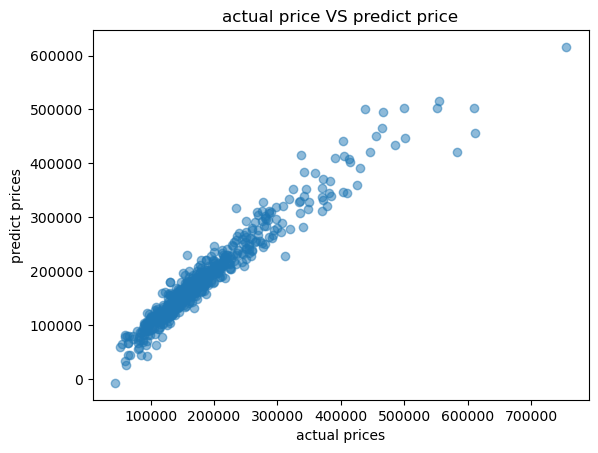

In [130]:
plt.scatter(y_test,y_pred,alpha=0.5)
plt.xlabel("actual prices")
plt.ylabel("predict prices")

plt.title("actual price VS predict price")
plt.savefig("img11.jpg")